<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/01_descarga_y_preparacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import drive
drive.mount('/content/drive')

!df -h /content | tail -1

Mounted at /content/drive
overlay         108G   22G   86G  21% /


In [8]:
!pip install -q kagglehub
import kagglehub

ruta = kagglehub.dataset_download("johnarevalo/mmimdb")
print("Descargado en:", ruta)
!ls -la {ruta}

Resuming download from 1577058304 bytes (2339561747 bytes left)...
Resuming download to /root/.cache/kagglehub/datasets/johnarevalo/mmimdb/1.archive (1577058304/3916620051) bytes left.


100%|██████████| 3.65G/3.65G [01:47<00:00, 21.8MB/s]

Extracting files...


Descargado en: /root/.cache/kagglehub/datasets/johnarevalo/mmimdb/versions/1
total 15337512
drwxr-xr-x 2 root root        4096 Oct 21 02:25 .
drwxr-xr-x 3 root root        4096 Oct 21 02:25 ..
-rw-r--r-- 1 root root    64463640 Oct 21 02:25 metadata.npy
-rw-r--r-- 1 root root 15641130233 Oct 21 02:27 multimodal_imdb.hdf5


In [9]:
import h5py, numpy as np, os

h5_path = os.path.join(ruta, 'multimodal_imdb.hdf5')
f = h5py.File(h5_path, 'r')   # 'r' = solo lectura; no carga nada todavía

print("=== Tablas dentro del HDF5 ===")
def mostrar(nombre, obj):
    if isinstance(obj, h5py.Dataset):
        print(f"{nombre:25s} forma={str(obj.shape):25s} tipo={obj.dtype}")
f.visititems(mostrar)

print("\n=== Atributos ===", list(f.attrs.keys()))
if 'split' in f.attrs:
    print("\n=== Particiones ===")
    for fila in f.attrs['split']:
        print(fila)

=== Tablas dentro del HDF5 ===
features                  forma=(25959, 300)              tipo=float32
genres                    forma=(25959, 23)               tipo=int32
images                    forma=(25959, 3, 256, 160)      tipo=int32
imdb_ids                  forma=(25959,)                  tipo=|S7
sequences                 forma=(25959,)                  tipo=object
three_grams               forma=(25959, 9946)             tipo=float32
vgg_features              forma=(25959, 4096)             tipo=float32
word_grams                forma=(25959, 13253)            tipo=float32

=== Atributos === ['split']

=== Particiones ===
(b'train', b'features', 0, 15552, <HDF5 object reference (null)>, True, b'.')
(b'train', b'genres', 0, 15552, <HDF5 object reference (null)>, True, b'.')
(b'train', b'images', 0, 15552, <HDF5 object reference (null)>, True, b'.')
(b'train', b'imdb_ids', 0, 15552, <HDF5 object reference (null)>, True, b'.')
(b'train', b'sequences', 0, 15552, <HDF5 object refe

In [10]:
meta = np.load(os.path.join(ruta, 'metadata.npy'), allow_pickle=True)
print("Tipo:", type(meta), "| forma:", getattr(meta, 'shape', None))

try:
    m = meta.item()
    print("Contenido:", type(m))
    if isinstance(m, dict):
        for k, v in m.items():
            tam = len(v) if hasattr(v, '__len__') else v
            print(f"  {k:20s} {type(v).__name__:12s} tamaño={tam}")
except Exception as e:
    print("No es un diccionario:", e)

Tipo: <class 'numpy.ndarray'> | forma: ()
Contenido: <class 'dict'>
  lookup               ndarray      tamaño=41611
  vocab_size           int          tamaño=69980
  word_to_ix           dict         tamaño=69980
  ix_to_word           dict         tamaño=69980


In [11]:
# Conteos de la Tabla 1 del paper (train, dev, test)
TABLA_PAPER = {
    'Drama': (8424, 1401, 4142), 'Comedy': (5108, 873, 2611), 'Romance': (3226, 548, 1590),
    'Thriller': (3113, 512, 1567), 'Crime': (2293, 382, 1163), 'Action': (2155, 351, 1044),
    'Adventure': (1611, 278, 821), 'Horror': (1603, 275, 825), 'Documentary': (1234, 219, 629),
    'Mystery': (1231, 209, 617), 'Sci-Fi': (1212, 193, 586), 'Fantasy': (1162, 186, 585),
    'Family': (978, 172, 518), 'Biography': (788, 144, 411), 'War': (806, 128, 401),
    'History': (680, 118, 345), 'Music': (634, 100, 311), 'Animation': (586, 105, 306),
    'Musical': (503, 85, 253), 'Western': (423, 72, 210), 'Sport': (379, 64, 191),
    'Short': (281, 48, 142), 'Film-Noir': (202, 34, 102),
}
CORTES = {'train': (0, 15552), 'dev': (15552, 18160), 'test': (18160, 25959)}

Y = f['genres'][:]   # pesa solo ~2 MB, se puede cargar completo
conteos = {s: Y[a:b].sum(axis=0) for s, (a, b) in CORTES.items()}

GENEROS = []
for j in range(Y.shape[1]):
    c = (int(conteos['train'][j]), int(conteos['dev'][j]), int(conteos['test'][j]))
    nombre = [g for g, v in TABLA_PAPER.items() if v == c]
    GENEROS.append(nombre[0] if nombre else f'DESCONOCIDO_{j}')
    print(f"columna {j:2d}: {c} -> {GENEROS[-1]}")

print("\nPelículas sin ningún género:", int((Y.sum(axis=1) == 0).sum()))
print("Promedio de géneros por película:", round(float(Y.sum(axis=1).mean()), 2))

columna  0: (8424, 1401, 4142) -> Drama
columna  1: (5108, 873, 2611) -> Comedy
columna  2: (3226, 548, 1590) -> Romance
columna  3: (3113, 512, 1567) -> Thriller
columna  4: (2293, 382, 1163) -> Crime
columna  5: (2155, 351, 1044) -> Action
columna  6: (1611, 278, 821) -> Adventure
columna  7: (1603, 275, 825) -> Horror
columna  8: (1234, 219, 629) -> Documentary
columna  9: (1231, 209, 617) -> Mystery
columna 10: (1212, 193, 586) -> Sci-Fi
columna 11: (1162, 186, 585) -> Fantasy
columna 12: (978, 172, 518) -> Family
columna 13: (788, 144, 411) -> Biography
columna 14: (806, 128, 401) -> War
columna 15: (680, 118, 345) -> History
columna 16: (634, 100, 311) -> Music
columna 17: (586, 105, 306) -> Animation
columna 18: (503, 85, 253) -> Musical
columna 19: (423, 72, 210) -> Western
columna 20: (379, 64, 191) -> Sport
columna 21: (281, 48, 142) -> Short
columna 22: (202, 34, 102) -> Film-Noir

Películas sin ningún género: 0
Promedio de géneros por película: 2.48


In [12]:
ix_to_word = m['ix_to_word']
seqs = f['sequences'][:]   # arreglo de listas de números, pesa poco

def decodificar(seq):
    return ' '.join(str(ix_to_word.get(int(i), ix_to_word.get(str(int(i)), '?'))) for i in seq)

for k in [0, 1, 2]:
    activos = [GENEROS[j] for j in np.where(Y[k] == 1)[0]]
    print(f"--- Película {k} | {f['imdb_ids'][k].decode()} | {activos}")
    print(decodificar(seqs[k])[:400], "...\n")

largos = np.array([len(s) for s in seqs])
print(f"Largo en palabras: media={largos.mean():.1f} | mediana={np.median(largos):.0f} | máx={largos.max()}")
print(f"Sinopsis con más de 55 palabras (aprox. superan los 77 tokens de CLIP): {(largos > 55).mean():.1%}")

--- Película 0 | 0028219 | ['Drama', 'Thriller', 'Mystery', 'Film-Noir']
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a t ...

--- Película 1 | 0044863 | ['Drama', 'Crime', 'Adventure', 'Film-Noir']
a sultry night club singer , a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao . the singer is quickly hired by an american expatriate who runs the biggest casino in macao and has a thriving business in converting hot jewels into cash . her new boss thinks one of her traveling companions is a cop . one is - - but not the o ...

--- Película 2 | 0037795 | ['Drama', 'Thril

Rango de píxeles: -123 a 151


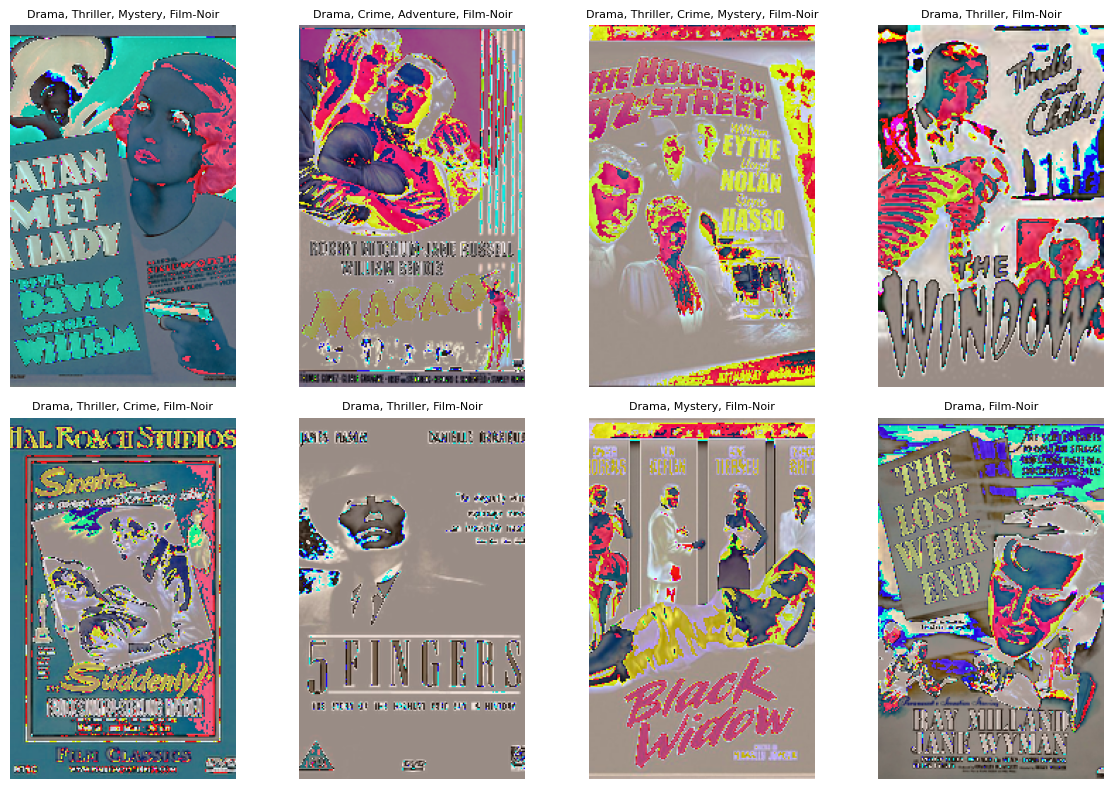

In [13]:
import matplotlib.pyplot as plt

muestra = f['images'][0:8]   # carga solo 8 imágenes, no las 25.959
print("Rango de píxeles:", muestra.min(), "a", muestra.max())

fig, axes = plt.subplots(2, 4, figsize=(12, 8))
for k, ax in enumerate(axes.flat):
    img = np.transpose(muestra[k], (1, 2, 0)).astype('uint8')   # (3,256,160) -> (256,160,3)
    ax.imshow(img)
    activos = [GENEROS[j] for j in np.where(Y[k] == 1)[0]]
    ax.set_title(', '.join(activos), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

Valores por canal (200 pósters):
  canal 0: min= -103.00  max=  151.00  media=   -7.68
  canal 1: min= -116.00  max=  138.00  media=   -5.82
  canal 2: min= -123.00  max=  131.00  media=    6.56


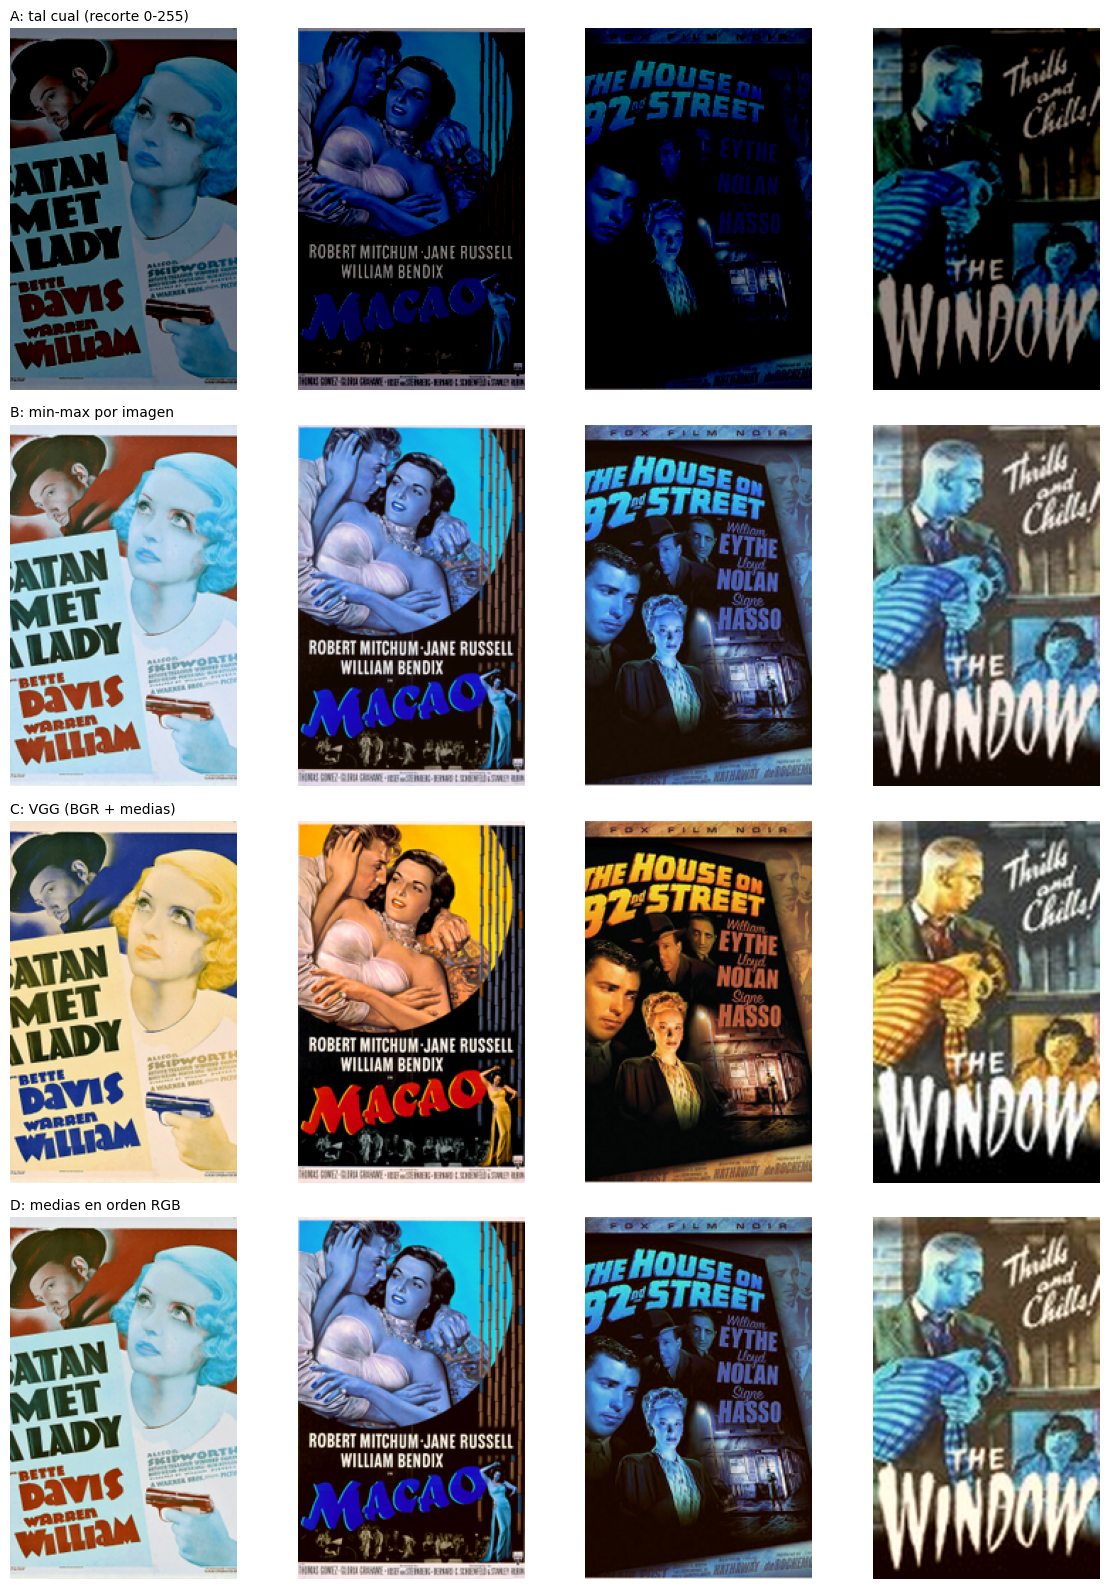

In [14]:
x = f['images'][0:200].astype(np.float32)
print("Valores por canal (200 pósters):")
for c in range(3):
    print(f"  canal {c}: min={x[:, c].min():8.2f}  max={x[:, c].max():8.2f}  media={x[:, c].mean():8.2f}")

def a_rgb(img, variante):
    """img: (3, 256, 160) -> (256, 160, 3) en uint8, según la hipótesis."""
    img = img.astype(np.float32)
    if variante == 'A: tal cual (recorte 0-255)':
        out = img
    elif variante == 'B: min-max por imagen':
        out = (img - img.min()) / (img.max() - img.min() + 1e-8) * 255
    elif variante == 'C: VGG (BGR + medias)':
        medias = np.array([103.939, 116.779, 123.68])[:, None, None]   # B, G, R
        out = (img + medias)[::-1]                                     # BGR -> RGB
    elif variante == 'D: medias en orden RGB':
        medias = np.array([123.68, 116.779, 103.939])[:, None, None]
        out = img + medias
    return np.clip(np.transpose(out, (1, 2, 0)), 0, 255).astype('uint8')

variantes = ['A: tal cual (recorte 0-255)', 'B: min-max por imagen',
             'C: VGG (BGR + medias)', 'D: medias en orden RGB']
fig, axes = plt.subplots(4, 4, figsize=(12, 16))
for fila, v in enumerate(variantes):
    for col in range(4):
        axes[fila, col].imshow(a_rgb(x[col], v))
        axes[fila, col].axis('off')
    axes[fila, 0].set_title(v, fontsize=10, loc='left')
plt.tight_layout()
plt.show()

In [15]:
import re

def limpiar_sinopsis(t):
    """Deshace la tokenización del HDF5 para que el texto se vea natural."""
    t = re.sub(r" ' (s|t|re|ve|ll|d|m)\b", r"'\1", t)   # partner ' s -> partner's
    t = re.sub(r" ([,.;:!?)\]])", r"\1", t)               # shane , -> shane,
    t = re.sub(r"([(\[]) ", r"\1", t)                     # ( texto -> (texto
    return t.strip()

def poster_a_rgb(img):
    """(3, 256, 160) en formato VGG (BGR, media restada) -> (256, 160, 3) RGB uint8."""
    medias_bgr = np.array([103.939, 116.779, 123.68], dtype=np.float32)[:, None, None]
    rgb = (img.astype(np.float32) + medias_bgr)[::-1]
    return np.clip(np.rint(np.transpose(rgb, (1, 2, 0))), 0, 255).astype(np.uint8)

for k in [0, 1]:
    print("ANTES  :", decodificar(seqs[k])[:200])
    print("DESPUÉS:", limpiar_sinopsis(decodificar(seqs[k]))[:200], "\n")

ANTES  : sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethoug
DESPUÉS: sardonic detective shane, thrown out of one town for bringing trouble, heads for home and his ex - partner's detective agency. the business is in a sad way, and shane, who has had the forethought to p 

ANTES  : a sultry night club singer , a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao . the singer is quickly hired by an american 
DESPUÉS: a sultry night club singer, a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao. the singer is quickly hired by an american ex 



In [16]:
import pandas as pd

ids = [x.decode() for x in f['imdb_ids'][:]]
particion = np.empty(len(ids), dtype=object)
for nombre, (a, b) in CORTES.items():
    particion[a:b] = nombre

df = pd.DataFrame({
    'fila_hdf5': np.arange(len(ids)),   # para encontrar el póster en el HDF5
    'imdb_id': ids,
    'particion': particion,
    'sinopsis': [limpiar_sinopsis(decodificar(s)) for s in seqs],
})
df[GENEROS] = Y

destino = '/content/drive/MyDrive/proyecto_multimodal/data'
os.makedirs(destino, exist_ok=True)
df.to_parquet(f'{destino}/mmimdb_meta.parquet', index=False)

print(df['particion'].value_counts())
print("Columnas:", df.shape[1], "| Filas:", df.shape[0])
!ls -lh {destino}

particion
train    15552
test      7799
dev       2608
Name: count, dtype: int64
Columnas: 27 | Filas: 25959
total 11M
-rw------- 1 root root 11M Oct 21 02:28 mmimdb_meta.parquet


In [17]:
import re

def limpiar_sinopsis(t):
    """Deshace la tokenización del HDF5 para que el texto se vea natural."""
    t = re.sub(r" ' (s|t|re|ve|ll|d|m)\b", r"'\1", t)   # partner ' s -> partner's
    t = re.sub(r" ([,.;:!?)\]])", r"\1", t)               # shane , -> shane,
    t = re.sub(r"([(\[]) ", r"\1", t)                     # ( texto -> (texto
    return t.strip()

def poster_a_rgb(img):
    """(3, 256, 160) en formato VGG (BGR, media restada) -> (256, 160, 3) RGB uint8."""
    medias_bgr = np.array([103.939, 116.779, 123.68], dtype=np.float32)[:, None, None]
    rgb = (img.astype(np.float32) + medias_bgr)[::-1]
    return np.clip(np.rint(np.transpose(rgb, (1, 2, 0))), 0, 255).astype(np.uint8)

for k in [0, 1]:
    print("ANTES  :", decodificar(seqs[k])[:200])
    print("DESPUÉS:", limpiar_sinopsis(decodificar(seqs[k]))[:200], "\n")

ANTES  : sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethoug
DESPUÉS: sardonic detective shane, thrown out of one town for bringing trouble, heads for home and his ex - partner's detective agency. the business is in a sad way, and shane, who has had the forethought to p 

ANTES  : a sultry night club singer , a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao . the singer is quickly hired by an american 
DESPUÉS: a sultry night club singer, a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao. the singer is quickly hired by an american ex 



In [18]:
import pandas as pd

ids = [x.decode() for x in f['imdb_ids'][:]]
particion = np.empty(len(ids), dtype=object)
for nombre, (a, b) in CORTES.items():
    particion[a:b] = nombre

df = pd.DataFrame({
    'fila_hdf5': np.arange(len(ids)),   # para encontrar el póster en el HDF5
    'imdb_id': ids,
    'particion': particion,
    'sinopsis': [limpiar_sinopsis(decodificar(s)) for s in seqs],
})
df[GENEROS] = Y

destino = '/content/drive/MyDrive/proyecto_multimodal/data'
os.makedirs(destino, exist_ok=True)
df.to_parquet(f'{destino}/mmimdb_meta.parquet', index=False)

print(df['particion'].value_counts())
print("Columnas:", df.shape[1], "| Filas:", df.shape[0])
!ls -lh {destino}

particion
train    15552
test      7799
dev       2608
Name: count, dtype: int64
Columnas: 27 | Filas: 25959
total 11M
-rw------- 1 root root 11M Oct 21 02:30 mmimdb_meta.parquet
